Step 1 — Import library dan membaca data

Step 1A Import library dan load dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# Membaca dataset
df_met = pd.read_csv("/content/drive/MyDrive/ml2/meteorologi_kalimantan_tengah.csv")
df_hotspot = pd.read_csv("/content/drive/MyDrive/ml2/hotspot_kalimantan_tengah.csv")

print("DATA METEOROLOGI")
print("Shape:", df_met.shape)
display(df_met.head())

print("\nDATA HOTSPOT")
print("Shape:", df_hotspot.shape)
display(df_hotspot.head())

DATA METEOROLOGI
Shape: (10555, 6)


,tanggal,T2M,RH2M,PRECTOTCORR,WS10M,lokasi
0,2021-01-01,25.87,90.30,5.21,0.52,Palangka Raya
1,2021-01-02,26.02,89.26,1.50,0.51,Palangka Raya
2,2021-01-03,26.45,88.98,9.02,0.72,Palangka Raya
3,2021-01-04,26.30,91.03,9.64,0.74,Palangka Raya
4,2021-01-05,25.69,92.79,5.07,0.55,Palangka Raya



DATA HOTSPOT
Shape: (178732, 15)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-3.37586,112.50913,332.88,0.40,0.37,2021-01-06,551,SNPP,SNPP,n,2,295.89,2.64,D,0.0
1,-3.06813,112.53498,332.70,0.39,0.37,2021-01-06,551,SNPP,SNPP,n,2,295.64,2.44,D,0.0
2,-0.99559,113.52280,341.73,0.41,0.61,2021-01-20,630,SNPP,SNPP,n,2,277.39,5.09,D,0.0
3,-2.55898,111.15220,333.39,0.43,0.38,2021-01-21,610,SNPP,SNPP,n,2,296.49,4.76,D,0.0
4,-2.55549,111.15167,335.33,0.43,0.38,2021-01-21,610,SNPP,SNPP,n,2,296.73,4.76,D,0.0


Step 1B Audit kualitas data

In [ ]:
# Fungsi audit dataset
def audit_data(df, nama, kolom_tanggal):
    print(f"\n{'=' * 45}")
    print(f"AUDIT DATA: {nama}")
    print(f"{'=' * 45}")

    print("Jumlah baris dan kolom:", df.shape)

    print("\nTipe data:")
    print(df.dtypes)

    print("\nNilai kosong:")
    print(df.isna().sum())

    print("\nJumlah baris duplikat:", df.duplicated().sum())

    tanggal = pd.to_datetime(df[kolom_tanggal], errors="coerce")
    print("\nTanggal awal:", tanggal.min())
    print("Tanggal akhir:", tanggal.max())
    print("Tanggal tidak valid:", tanggal.isna().sum())


audit_data(df_met, "Meteorologi", "tanggal")
audit_data(df_hotspot, "Hotspot", "acq_date")


AUDIT DATA: Meteorologi
Jumlah baris dan kolom: (10555, 6)

Tipe data:
tanggal         object
T2M            float64
RH2M           float64
PRECTOTCORR    float64
WS10M          float64
lokasi          object
dtype: object

Nilai kosong:
tanggal        0
T2M            0
RH2M           0
PRECTOTCORR    0
WS10M          0
lokasi         0
dtype: int64

Jumlah baris duplikat: 0

Tanggal awal: 2021-01-01 00:00:00
Tanggal akhir: 2026-10-12 00:00:00
Tanggal tidak valid: 0

AUDIT DATA: Hotspot
Jumlah baris dan kolom: (178732, 15)

Tipe data:
latitude      float64
longitude     float64
brightness    float64
scan          float64
track         float64
acq_date       object
acq_time        int64
satellite      object
instrument     object
confidence     object
version        object
bright_t31    float64
frp           float64
daynight       object
type          float64
dtype: object

Nilai kosong:
latitude           0
longitude          0
brightness         0
scan               0
track         

Step 1C — Membersihkan data

In [ ]:
# Salin dataset agar data asli tetap aman
df_met_clean = df_met.copy()
df_hotspot_clean = df_hotspot.copy()

# Konversi tanggal
df_met_clean["tanggal"] = pd.to_datetime(
    df_met_clean["tanggal"], errors="coerce"
)

df_hotspot_clean["acq_date"] = pd.to_datetime(
    df_hotspot_clean["acq_date"], errors="coerce"
)

# Ganti nilai penanda missing pada meteorologi
kolom_met = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

df_met_clean[kolom_met] = (
    df_met_clean[kolom_met]
    .replace(-999, np.nan)
)

# Hapus baris yang tanggalnya tidak valid
df_met_clean = df_met_clean.dropna(subset=["tanggal"])
df_hotspot_clean = df_hotspot_clean.dropna(
    subset=["acq_date", "latitude", "longitude"]
)

# Periksa hasil
print("Missing meteorologi setelah pembersihan:")
print(df_met_clean[kolom_met].isna().sum())

print("\nJumlah baris meteorologi:", len(df_met_clean))
print("Jumlah baris hotspot:", len(df_hotspot_clean))

Missing meteorologi setelah pembersihan:
T2M            15
RH2M           15
PRECTOTCORR    15
WS10M          15
dtype: int64

Jumlah baris meteorologi: 10555
Jumlah baris hotspot: 178732


Step 1D — Validasi rentang dan koordinat

In [ ]:
print("Rentang tanggal meteorologi:")
print(df_met_clean["tanggal"].min(),
      "sampai",
      df_met_clean["tanggal"].max())

print("\nRentang tanggal hotspot:")
print(df_hotspot_clean["acq_date"].min(),
      "sampai",
      df_hotspot_clean["acq_date"].max())

print("\nRentang koordinat hotspot:")
print("Latitude:",
      df_hotspot_clean["latitude"].min(),
      "sampai",
      df_hotspot_clean["latitude"].max())

print("Longitude:",
      df_hotspot_clean["longitude"].min(),
      "sampai",
      df_hotspot_clean["longitude"].max())

print("\nJumlah lokasi meteorologi:")
print(df_met_clean["lokasi"].value_counts())

Rentang tanggal meteorologi:
2021-01-01 00:00:00 sampai 2026-10-12 00:00:00

Rentang tanggal hotspot:
2021-01-06 00:00:00 sampai 2026-10-12 00:00:00

Rentang koordinat hotspot:
Latitude: -3.51689 sampai -0.00031
Longitude: 110.75585 sampai 115.71839

Jumlah lokasi meteorologi:
lokasi
Palangka Raya    2111
Sampit           2111
Pangkalan Bun    2111
Muara Teweh      2111
Kuala Kapuas     2111
Name: count, dtype: int64


1E membersihkan nilai kosong dan memeriksa missing

In [ ]:
# Salin data agar dataset asli tetap aman
df_met_clean = df_met.copy()
df_hotspot_clean = df_hotspot.copy()

# Ubah kolom tanggal menjadi datetime
df_met_clean["tanggal"] = pd.to_datetime(
    df_met_clean["tanggal"], errors="coerce"
)

df_hotspot_clean["acq_date"] = pd.to_datetime(
    df_hotspot_clean["acq_date"], errors="coerce"
)

# Ganti penanda -999 menjadi NaN
kolom_met = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

df_met_clean[kolom_met] = (
    df_met_clean[kolom_met].replace(-999, np.nan)
)

# Periksa jumlah missing setiap variabel
print("Missing setiap variabel:")
print(df_met_clean[kolom_met].isna().sum())

# Periksa apakah missing terjadi pada baris yang sama
mask_missing = df_met_clean[kolom_met].isna().any(axis=1)

print("\nJumlah baris dengan minimal satu missing:",
      mask_missing.sum())

print("\nBaris meteorologi yang memiliki missing:")
display(
    df_met_clean.loc[
        mask_missing,
        ["tanggal", "lokasi"] + kolom_met
    ]
)

# Periksa apakah satu tanggal-lokasi muncul lebih dari sekali
print("\nDuplikasi kombinasi tanggal dan lokasi:",
      df_met_clean.duplicated(
          subset=["tanggal", "lokasi"]
      ).sum())

Missing setiap variabel:
T2M            15
RH2M           15
PRECTOTCORR    15
WS10M          15
dtype: int64

Jumlah baris dengan minimal satu missing: 15

Baris meteorologi yang memiliki missing:


,tanggal,lokasi,T2M,RH2M,PRECTOTCORR,WS10M
2108,2026-10-10,Palangka Raya,NaN,NaN,NaN,NaN
2109,2026-10-11,Palangka Raya,NaN,NaN,NaN,NaN
2110,2026-10-12,Palangka Raya,NaN,NaN,NaN,NaN
4219,2026-10-10,Sampit,NaN,NaN,NaN,NaN
4220,2026-10-11,Sampit,NaN,NaN,NaN,NaN
4221,2026-10-12,Sampit,NaN,NaN,NaN,NaN
6330,2026-10-10,Pangkalan Bun,NaN,NaN,NaN,NaN
6331,2026-10-11,Pangkalan Bun,NaN,NaN,NaN,NaN
6332,2026-10-12,Pangkalan Bun,NaN,NaN,NaN,NaN
8441,2026-10-10,Muara Teweh,NaN,NaN,NaN,NaN



Duplikasi kombinasi tanggal dan lokasi: 0


Step 1F — Memeriksa koordinat hotspot

In [ ]:
print("Latitude di luar rentang geografis:")
print(
    (~df_hotspot_clean["latitude"].between(-90, 90)).sum()
)

print("\nLongitude di luar rentang geografis:")
print(
    (~df_hotspot_clean["longitude"].between(-180, 180)).sum()
)

print("\nJumlah tanggal unik hotspot:",
      df_hotspot_clean["acq_date"].nunique())

print("Jumlah tanggal unik meteorologi:",
      df_met_clean["tanggal"].nunique())

Latitude di luar rentang geografis:
0

Longitude di luar rentang geografis:
0

Jumlah tanggal unik hotspot: 1308
Jumlah tanggal unik meteorologi: 2111


Step 1G — Menentukan periode data yang layak

In [ ]:
# Identifikasi tanggal ketika semua variabel meteorologi tersedia
tanggal_lengkap = (
    df_met_clean.groupby("tanggal")[kolom_met]
    .apply(lambda x: x.notna().all().all())
)

tanggal_akhir_lengkap = tanggal_lengkap[
    tanggal_lengkap
].index.max()

print("Tanggal terakhir dengan meteorologi lengkap:",
      tanggal_akhir_lengkap)

# Batasi kedua dataset pada periode meteorologi lengkap
df_met_clean = df_met_clean[
    df_met_clean["tanggal"] <= tanggal_akhir_lengkap
].copy()

df_hotspot_clean = df_hotspot_clean[
    df_hotspot_clean["acq_date"] <= tanggal_akhir_lengkap
].copy()

print("\nHasil setelah pembatasan periode:")
print("Meteorologi:", df_met_clean.shape)
print("Hotspot:", df_hotspot_clean.shape)

print("\nMissing meteorologi:")
print(df_met_clean[kolom_met].isna().sum())

print("\nRentang tanggal meteorologi:")
print(df_met_clean["tanggal"].min(),
      "sampai", df_met_clean["tanggal"].max())

print("\nRentang tanggal hotspot:")
print(df_hotspot_clean["acq_date"].min(),
      "sampai", df_hotspot_clean["acq_date"].max())

Tanggal terakhir dengan meteorologi lengkap: 2026-10-09 00:00:00

Hasil setelah pembatasan periode:
Meteorologi: (10540, 6)
Hotspot: (170985, 15)

Missing meteorologi:
T2M            0
RH2M           0
PRECTOTCORR    0
WS10M          0
dtype: int64

Rentang tanggal meteorologi:
2021-01-01 00:00:00 sampai 2026-10-09 00:00:00

Rentang tanggal hotspot:
2021-01-06 00:00:00 sampai 2026-10-09 00:00:00


Tahap 2 — Membentuk grid geografis Kalimantan Tengah

Step 2A — Instal dan import library geospasial

In [ ]:
!pip install geopandas shapely pyproj contextily

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box, Point
from pyproj import CRS

print("GeoPandas:", gpd.__version__)

GeoPandas: 1.2.0


CRS: EPSG:4326
Jumlah fitur: 1
Kolom: ['ID_0', 'COUNTRY', 'ID_1', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry']


,ID_0,COUNTRY,ID_1,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry
0,IDN,Indonesia,IDN.14_1,Kalimantan Tengah,None,None,Propinisi,Province,62,ID.KT,None,"MULTIPOLYGON (((111.79316 -3.52581, 111.79073 ..."


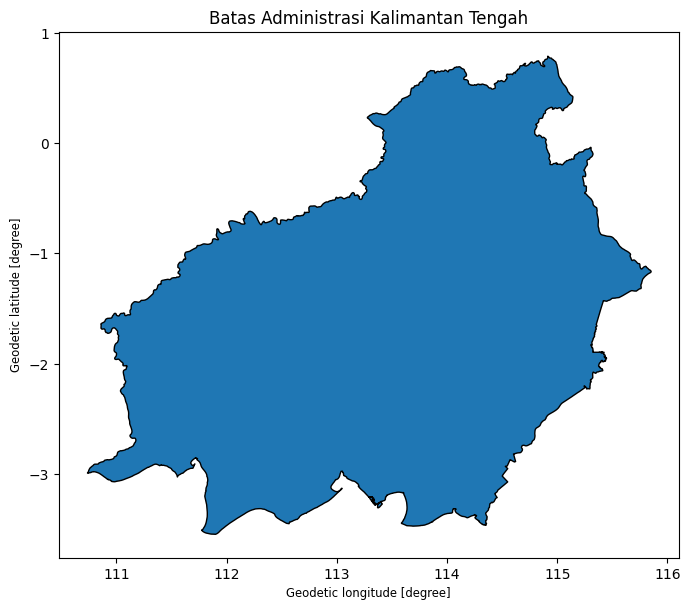

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Baca batas administrasi
gdf_kalteng = gpd.read_file("/content/drive/MyDrive/ml2/kalimantan_tengah.geojson")

print("CRS:", gdf_kalteng.crs)
print("Jumlah fitur:", len(gdf_kalteng))
print("Kolom:", gdf_kalteng.columns.tolist())

display(gdf_kalteng.head())

# Visualisasi batas
gdf_kalteng.plot(figsize=(8, 8), edgecolor="black")
plt.title("Batas Administrasi Kalimantan Tengah")
plt.show()

Step 2C — Proyeksi koordinat dan pembuatan grid

Jumlah grid: 1685
CRS grid: EPSG:32749


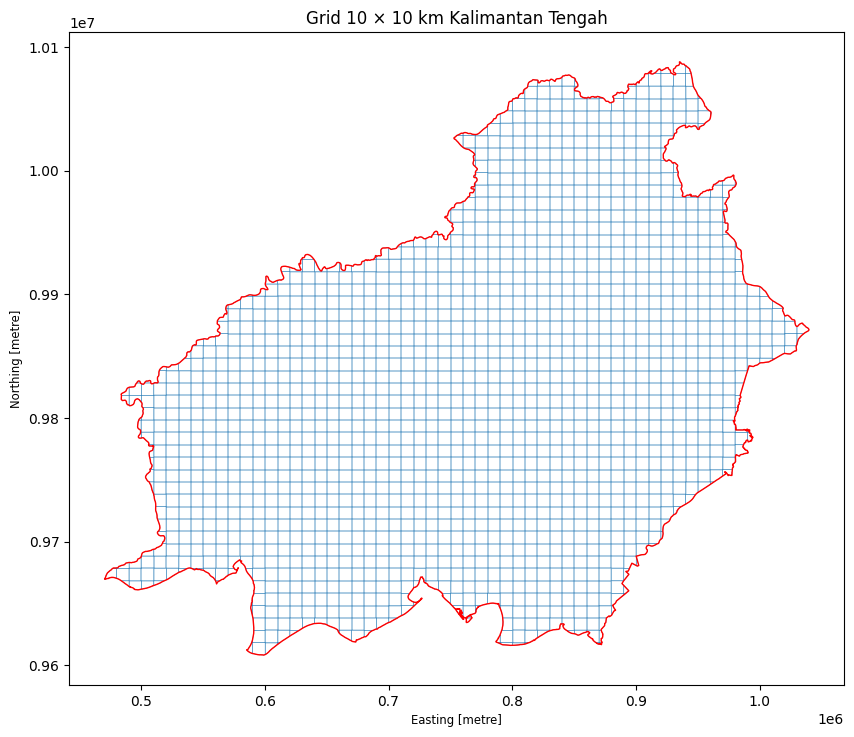

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# 1. Pastikan CRS batas provinsi benar
gdf_kalteng = gdf_kalteng.to_crs("EPSG:4326")

# 2. Gabungkan geometri provinsi menjadi satu polygon
batas_provinsi = gdf_kalteng.geometry.union_all()

gdf_batas = gpd.GeoDataFrame(
    {"wilayah": ["Kalimantan Tengah"]},
    geometry=[batas_provinsi],
    crs="EPSG:4326"
)

# 3. Proyeksikan ke CRS metrik yang sesuai
# UTM zona 49S mencakup sebagian besar Kalimantan Tengah,
# tetapi wilayah paling barat mungkin mendekati zona 48S.
# Untuk grid yang konsisten, gunakan proyeksi regional yang sesuai.
gdf_batas_m = gdf_batas.to_crs("EPSG:32749")

# 4. Buat grid berukuran 10.000 meter
ukuran_grid = 10_000

minx, miny, maxx, maxy = gdf_batas_m.total_bounds

grid_geometries = []

x = minx
while x < maxx:
    y = miny
    while y < maxy:
        cell = box(x, y, x + ukuran_grid, y + ukuran_grid)

        # Simpan hanya grid yang beririsan dengan provinsi
        if cell.intersects(gdf_batas_m.geometry.iloc[0]):
            grid_geometries.append(cell)

        y += ukuran_grid
    x += ukuran_grid

gdf_grid = gpd.GeoDataFrame(
    geometry=grid_geometries,
    crs=gdf_batas_m.crs
)

# Beri ID unik untuk setiap grid
gdf_grid["grid_id"] = [
    f"GRID_{i:04d}" for i in range(1, len(gdf_grid) + 1)
]

# Potong grid sesuai batas provinsi
gdf_grid = gpd.overlay(
    gdf_grid,
    gdf_batas_m,
    how="intersection"
)

print("Jumlah grid:", len(gdf_grid))
print("CRS grid:", gdf_grid.crs)

# Visualisasi
ax = gdf_grid.boundary.plot(
    figsize=(10, 10),
    linewidth=0.3
)
gdf_batas_m.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1
)
plt.title("Grid 10 × 10 km Kalimantan Tengah")
plt.show()

Step 2D — Memetakan titik hotspot ke batas provinsi


In [ ]:
# Pastikan data hotspot memakai CRS geografis
gdf_hotspot = gpd.GeoDataFrame(
    df_hotspot_clean.copy(),
    geometry=gpd.points_from_xy(
        df_hotspot_clean["longitude"],
        df_hotspot_clean["latitude"]
    ),
    crs="EPSG:4326"
)

# Transformasikan ke CRS grid
gdf_hotspot_m = gdf_hotspot.to_crs(gdf_grid.crs)

# Periksa titik di dalam batas provinsi
batas_m = gdf_batas_m.geometry.iloc[0]

mask_dalam = gdf_hotspot_m.geometry.within(batas_m)

print("Total hotspot:", len(gdf_hotspot_m))
print("Hotspot di dalam provinsi:", mask_dalam.sum())
print("Hotspot di luar provinsi:", (~mask_dalam).sum())

Total hotspot: 170985
Hotspot di dalam provinsi: 170816
Hotspot di luar provinsi: 169


Step 2E — Memperbaiki proyeksi dan memfinalkan grid

CRS: +proj=laea +lat_0=-1.5 +lon_0=113.5 +datum=WGS84 +units=m +no_defs +type=crs
Jumlah grid: 1681


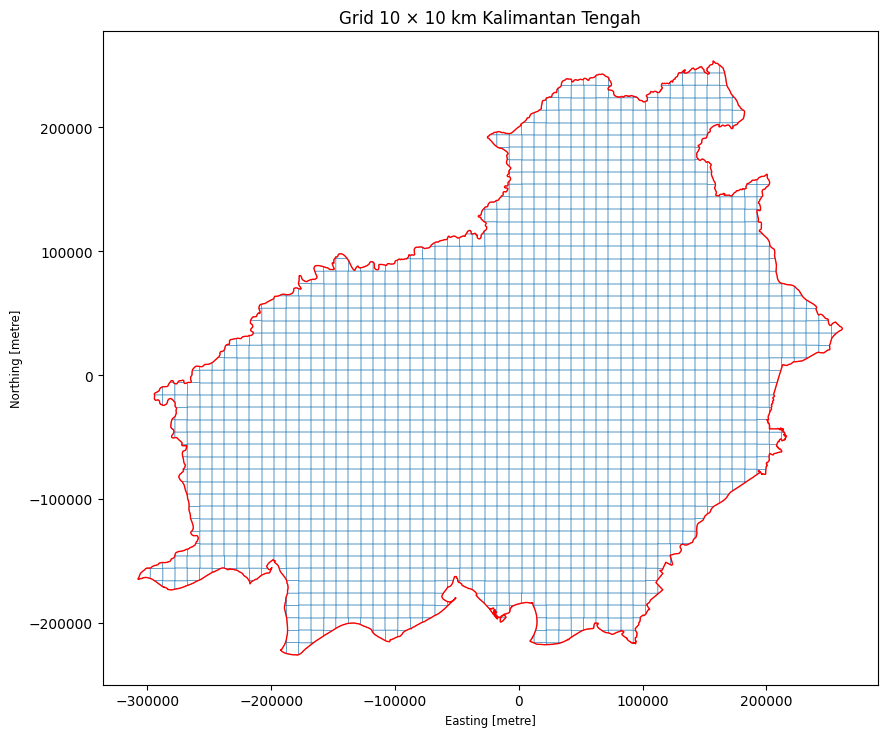

In [ ]:
from pyproj import CRS
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# Proyeksi equal-area berpusat pada Kalimantan Tengah
crs_laea = CRS.from_proj4(
    "+proj=laea +lat_0=-1.5 +lon_0=113.5 "
    "+datum=WGS84 +units=m +no_defs"
)

# Proyeksikan batas provinsi
gdf_batas_laea = gdf_batas.to_crs(crs_laea)

batas_laea = gdf_batas_laea.geometry.iloc[0]
minx, miny, maxx, maxy = gdf_batas_laea.total_bounds

ukuran_grid = 10_000
grid_geometries = []

x = minx
while x < maxx:
    y = miny
    while y < maxy:
        cell = box(x, y, x + ukuran_grid, y + ukuran_grid)

        if cell.intersects(batas_laea):
            grid_geometries.append(cell)

        y += ukuran_grid
    x += ukuran_grid

gdf_grid = gpd.GeoDataFrame(
    {"geometry": grid_geometries},
    crs=crs_laea
)

# Potong grid pada batas provinsi
gdf_grid = gpd.overlay(
    gdf_grid,
    gdf_batas_laea,
    how="intersection"
)

gdf_grid = gdf_grid.reset_index(drop=True)
gdf_grid["grid_id"] = [
    f"GRID_{i:04d}" for i in range(1, len(gdf_grid) + 1)
]

print("CRS:", gdf_grid.crs)
print("Jumlah grid:", len(gdf_grid))

ax = gdf_grid.boundary.plot(
    figsize=(10, 10),
    linewidth=0.3
)
gdf_batas_laea.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1
)
plt.title("Grid 10 × 10 km Kalimantan Tengah")
plt.show()

Step 2F — Memetakan hotspot ke grid final

In [ ]:
# Buat titik hotspot dalam CRS geografis
gdf_hotspot = gpd.GeoDataFrame(
    df_hotspot_clean.copy(),
    geometry=gpd.points_from_xy(
        df_hotspot_clean["longitude"],
        df_hotspot_clean["latitude"]
    ),
    crs="EPSG:4326"
)

# Proyeksikan ke CRS grid final
gdf_hotspot = gdf_hotspot.to_crs(gdf_grid.crs)

# Ambil hanya hotspot di dalam batas provinsi
mask_dalam = gdf_hotspot.geometry.within(batas_laea)

gdf_hotspot_dalam = gdf_hotspot.loc[mask_dalam].copy()

print("Total hotspot awal:", len(gdf_hotspot))
print("Hotspot dalam provinsi:", len(gdf_hotspot_dalam))
print("Hotspot di luar provinsi:", (~mask_dalam).sum())

Total hotspot awal: 170985
Hotspot dalam provinsi: 170816
Hotspot di luar provinsi: 169


Step 2G — Memetakan hotspot ke grid dan menghitung jumlah harian

In [ ]:
# 1. Ambil hotspot yang berada di dalam batas provinsi
mask_dalam = gdf_hotspot.geometry.intersects(batas_laea)
gdf_hotspot_dalam = gdf_hotspot.loc[mask_dalam].copy()

# 2. Petakan setiap titik hotspot ke grid
hotspot_grid = gpd.sjoin(
    gdf_hotspot_dalam,
    gdf_grid[["grid_id", "geometry"]],
    how="inner",
    predicate="within"
)

# 3. Hitung jumlah deteksi per grid per tanggal
hotspot_harian = (
    hotspot_grid
    .groupby(["grid_id", "acq_date"])
    .size()
    .reset_index(name="jumlah_hotspot")
)

print("Jumlah baris hotspot harian:", len(hotspot_harian))
print("Jumlah grid yang memiliki deteksi:",
      hotspot_harian["grid_id"].nunique())
print("Jumlah tanggal dengan deteksi:",
      hotspot_harian["acq_date"].nunique())

display(hotspot_harian.head())

Jumlah baris hotspot harian: 31660
Jumlah grid yang memiliki deteksi: 1266
Jumlah tanggal dengan deteksi: 1304


,grid_id,acq_date,jumlah_hotspot
0,GRID_0001,2023-08-12,1
1,GRID_0001,2023-08-29,1
2,GRID_0001,2023-09-15,2
3,GRID_0001,2023-10-25,1
4,GRID_0001,2023-10-26,2


Step 2H — Membentuk kalender lengkap

In [ ]:
# Kalender periode meteorologi lengkap
tanggal_awal = df_met_clean["tanggal"].min()
tanggal_akhir = df_met_clean["tanggal"].max()

kalender = pd.date_range(
    start=tanggal_awal,
    end=tanggal_akhir,
    freq="D"
)

# Seluruh kombinasi grid dan tanggal
index_grid_tanggal = pd.MultiIndex.from_product(
    [gdf_grid["grid_id"], kalender],
    names=["grid_id", "tanggal"]
)

panel_hotspot = (
    hotspot_harian
    .rename(columns={"acq_date": "tanggal"})
    .set_index(["grid_id", "tanggal"])
    .reindex(index_grid_tanggal, fill_value=0)
    .reset_index()
)

print("Jumlah baris panel:", len(panel_hotspot))
print("Jumlah grid:", panel_hotspot["grid_id"].nunique())
print("Jumlah tanggal:", panel_hotspot["tanggal"].nunique())
print("\nDistribusi jumlah hotspot per grid-hari:")
print(panel_hotspot["jumlah_hotspot"].describe())

display(panel_hotspot.head())

Jumlah baris panel: 3543548
Jumlah grid: 1681
Jumlah tanggal: 2108

Distribusi jumlah hotspot per grid-hari:
count    3.543548e+06
mean     4.820479e-02
std      1.198982e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.590000e+02
Name: jumlah_hotspot, dtype: float64


,grid_id,tanggal,jumlah_hotspot
0,GRID_0001,2021-01-01,0
1,GRID_0001,2021-01-02,0
2,GRID_0001,2021-01-03,0
3,GRID_0001,2021-01-04,0
4,GRID_0001,2021-01-05,0


Step 3 — Analisis spasial menggunakan DBSCAN

Step 3A — Menyiapkan data koordinat

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Ambil koordinat hotspot dalam CRS regional
koordinat = np.column_stack([
    gdf_hotspot_dalam.geometry.x,
    gdf_hotspot_dalam.geometry.y
])

print("Jumlah titik untuk DBSCAN:", len(koordinat))
print("Bentuk matriks koordinat:", koordinat.shape)

Jumlah titik untuk DBSCAN: 170816
Bentuk matriks koordinat: (170816, 2)


Step 3B — Menentukan parameter awal DBSCAN

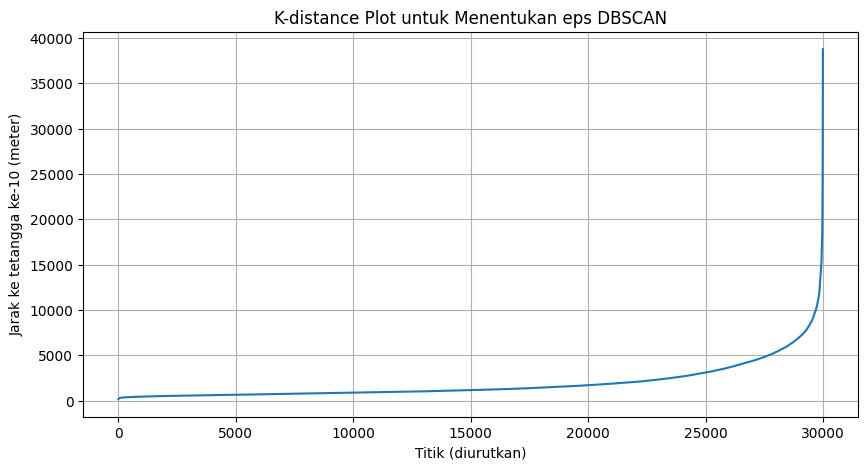

In [ ]:
# Gunakan sampel untuk eksplorasi parameter
rng = np.random.default_rng(42)

n_sample = min(30000, len(koordinat))
idx = rng.choice(len(koordinat), size=n_sample, replace=False)
koordinat_sample = koordinat[idx]

# Jarak ke tetangga ke-10
neighbors = NearestNeighbors(
    n_neighbors=10,
    algorithm="kd_tree"
)

neighbors.fit(koordinat_sample)
distances, _ = neighbors.kneighbors(koordinat_sample)

k_distance = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distance)
plt.xlabel("Titik (diurutkan)")
plt.ylabel("Jarak ke tetangga ke-10 (meter)")
plt.title("K-distance Plot untuk Menentukan eps DBSCAN")
plt.grid(True)
plt.show()

Step 3C — Menguji kandidat parameter DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN
import pandas as pd

kandidat_eps = [2000, 3000, 5000]
hasil_uji = []

for eps in kandidat_eps:
    model = DBSCAN(
        eps=eps,
        min_samples=10,
        algorithm="kd_tree",
        n_jobs=-1
    )

    label = model.fit_predict(koordinat_sample)

    n_noise = (label == -1).sum()
    klaster = set(label) - {-1}

    hasil_uji.append({
        "eps_meter": eps,
        "jumlah_klaster": len(klaster),
        "jumlah_noise": n_noise,
        "persentase_noise": round(
            n_noise / len(label) * 100, 2
        )
    })

hasil_uji = pd.DataFrame(hasil_uji)
display(hasil_uji)

,eps_meter,jumlah_klaster,jumlah_noise,persentase_noise
0,2000,245,6116,20.39
1,3000,189,3744,12.48
2,5000,106,1219,4.06


Step 3D — Menjalankan DBSCAN pada seluruh data

In [ ]:
# DBSCAN pada seluruh titik hotspot
dbscan_final = DBSCAN(
    eps=3000,
    min_samples=10,
    algorithm="kd_tree",
    n_jobs=-1
)

label_dbscan = dbscan_final.fit_predict(koordinat)

# Simpan label ke data hotspot
gdf_hotspot_dalam = gdf_hotspot_dalam.copy()
gdf_hotspot_dalam["cluster_dbscan"] = label_dbscan

# Ringkasan hasil
jumlah_noise = (label_dbscan == -1).sum()
jumlah_klaster = len(set(label_dbscan) - {-1})

print("Jumlah titik:", len(label_dbscan))
print("Jumlah klaster:", jumlah_klaster)
print("Jumlah noise:", jumlah_noise)
print(
    "Persentase noise:",
    round(jumlah_noise / len(label_dbscan) * 100, 2), "%"
)

print("\nLima klaster terbesar:")
print(
    gdf_hotspot_dalam.loc[
        gdf_hotspot_dalam["cluster_dbscan"] != -1,
        "cluster_dbscan"
    ].value_counts().head()
)

Jumlah titik: 170816
Jumlah klaster: 214
Jumlah noise: 1900
Persentase noise: 1.11 %

Lima klaster terbesar:
cluster_dbscan
0     47405
5     39608
10    23191
32    14431
1      6059
Name: count, dtype: int64


Step 3E — Visualisasi hasil klaster

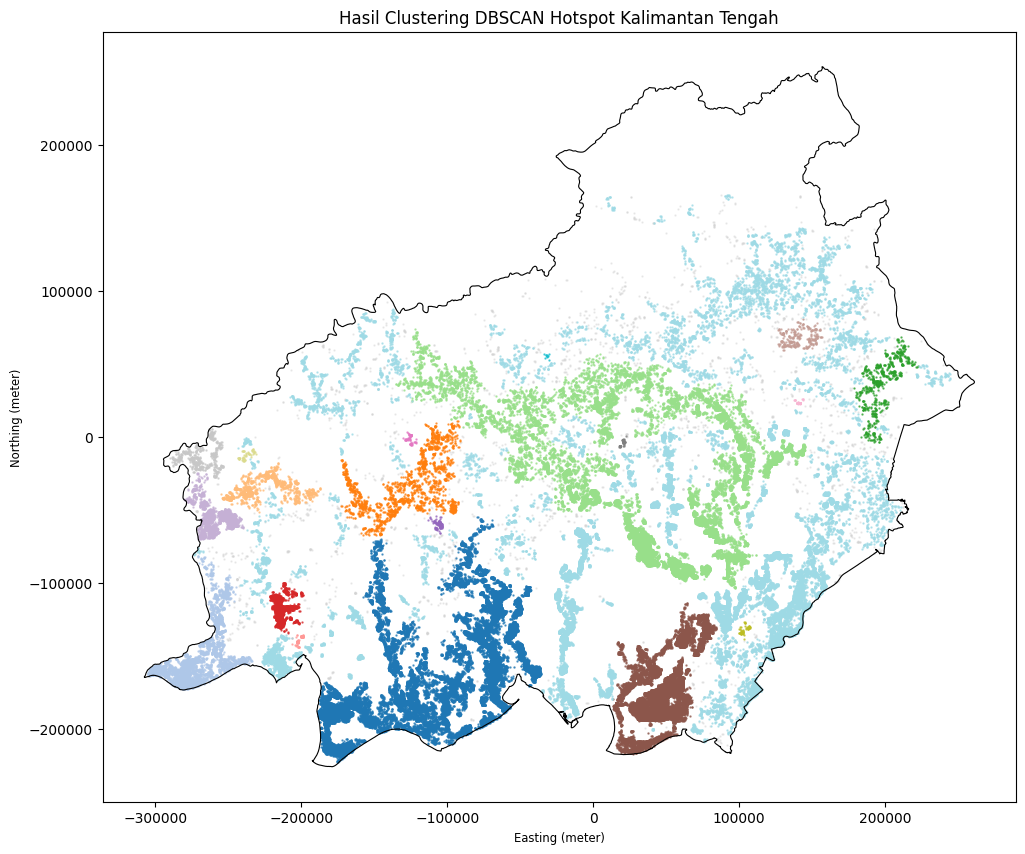

In [ ]:
import matplotlib.pyplot as plt

# Warna berbeda untuk setiap klaster; noise berwarna abu-abu
fig, ax = plt.subplots(figsize=(12, 10))

gdf_batas_laea.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

noise = gdf_hotspot_dalam[
    gdf_hotspot_dalam["cluster_dbscan"] == -1
]

klaster = gdf_hotspot_dalam[
    gdf_hotspot_dalam["cluster_dbscan"] != -1
]

noise.plot(
    ax=ax,
    color="lightgray",
    markersize=0.5,
    alpha=0.4,
    label="Noise"
)

klaster.plot(
    ax=ax,
    column="cluster_dbscan",
    categorical=True,
    markersize=0.5,
    alpha=0.7,
    legend=False
)

ax.set_title("Hasil Clustering DBSCAN Hotspot Kalimantan Tengah")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
plt.show()

Step 4A — Membentuk fitur riwayat hotspot

In [ ]:
# Pastikan panel sudah terurut
panel_hotspot = panel_hotspot.sort_values(
    ["grid_id", "tanggal"]
).reset_index(drop=True)

# Fitur riwayat hotspot per grid
grouped = panel_hotspot.groupby("grid_id")["jumlah_hotspot"]

panel_hotspot["hotspot_lag1"] = grouped.shift(1)
panel_hotspot["hotspot_lag3"] = grouped.shift(3)
panel_hotspot["hotspot_lag7"] = grouped.shift(7)

display(panel_hotspot.head(12))

,grid_id,tanggal,jumlah_hotspot,hotspot_lag1,hotspot_lag3,hotspot_lag7
0,GRID_0001,2021-01-01,0,NaN,NaN,NaN
1,GRID_0001,2021-01-02,0,0.0,NaN,NaN
2,GRID_0001,2021-01-03,0,0.0,NaN,NaN
3,GRID_0001,2021-01-04,0,0.0,0.0,NaN
4,GRID_0001,2021-01-05,0,0.0,0.0,NaN
5,GRID_0001,2021-01-06,0,0.0,0.0,NaN
6,GRID_0001,2021-01-07,0,0.0,0.0,NaN
7,GRID_0001,2021-01-08,0,0.0,0.0,0.0
8,GRID_0001,2021-01-09,0,0.0,0.0,0.0
9,GRID_0001,2021-01-10,0,0.0,0.0,0.0


Step 4B — Membentuk fitur kepadatan hotspot dari grid tetangga

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

# Pastikan grid memakai CRS metrik
centroid = gdf_grid.geometry.centroid

koordinat_grid = np.column_stack([
    centroid.x,
    centroid.y
])

# Cari grid dalam radius 15 km
radius_meter = 15_000

neighbors = NearestNeighbors(
    radius=radius_meter,
    algorithm="kd_tree"
)

neighbors.fit(koordinat_grid)

daftar_tetangga = neighbors.radius_neighbors(
    koordinat_grid,
    return_distance=False
)

# Buat pemetaan grid ke indeks
grid_ids = gdf_grid["grid_id"].tolist()
grid_index = {
    grid_id: i for i, grid_id in enumerate(grid_ids)
}

# Buat daftar tetangga untuk setiap grid
tetangga_grid = {
    grid_ids[i]: [
        grid_ids[j]
        for j in daftar_tetangga[i]
        if j != i
    ]
    for i in range(len(grid_ids))
}

print("Contoh grid:", grid_ids[0])
print("Jumlah tetangga:", len(tetangga_grid[grid_ids[0]]))

Contoh grid: GRID_0001
Jumlah tetangga: 4


Step 4C — Membentuk fitur jumlah hotspot tetangga

In [ ]:
from scipy.sparse import lil_matrix

# Urutan grid harus sama dengan urutan koordinat_grid
n_grid = len(grid_ids)

# Matriks ketetanggaan: 1 jika dua grid bertetangga
adjacency = lil_matrix((n_grid, n_grid), dtype=np.float32)

for i, grid_id in enumerate(grid_ids):
    for neighbor_id in tetangga_grid[grid_id]:
        j = grid_index[neighbor_id]
        adjacency[i, j] = 1

adjacency = adjacency.tocsr()

# Matriks jumlah hotspot: tanggal x grid
matriks_hotspot = (
    panel_hotspot
    .pivot(index="tanggal", columns="grid_id",
           values="jumlah_hotspot")
    .reindex(columns=grid_ids)
    .fillna(0)
)

# Geser satu hari: hanya menggunakan informasi hari sebelumnya
matriks_lag1 = matriks_hotspot.shift(1).fillna(0)

# Hitung jumlah hotspot pada seluruh grid tetangga
neighbor_counts = matriks_lag1.to_numpy() @ adjacency.T

# Kembalikan ke format tabel panjang
fitur_tetangga = pd.DataFrame(
    neighbor_counts,
    index=matriks_hotspot.index,
    columns=grid_ids
).rename_axis("tanggal").reset_index()

fitur_tetangga = fitur_tetangga.melt(
    id_vars="tanggal",
    var_name="grid_id",
    value_name="neighbor_hotspots_lag1"
)

# Gabungkan ke panel utama
panel_hotspot = panel_hotspot.merge(
    fitur_tetangga,
    on=["grid_id", "tanggal"],
    how="left",
    validate="one_to_one"
)

print(panel_hotspot[
    ["grid_id", "tanggal", "jumlah_hotspot",
     "hotspot_lag1", "neighbor_hotspots_lag1"]
].head(12))

      grid_id    tanggal  jumlah_hotspot  hotspot_lag1  neighbor_hotspots_lag1
0   GRID_0001 2021-01-01               0           NaN                     0.0
1   GRID_0001 2021-01-02               0           0.0                     0.0
2   GRID_0001 2021-01-03               0           0.0                     0.0
3   GRID_0001 2021-01-04               0           0.0                     0.0
4   GRID_0001 2021-01-05               0           0.0                     0.0
5   GRID_0001 2021-01-06               0           0.0                     0.0
6   GRID_0001 2021-01-07               0           0.0                     0.0
7   GRID_0001 2021-01-08               0           0.0                     0.0
8   GRID_0001 2021-01-09               0           0.0                     0.0
9   GRID_0001 2021-01-10               0           0.0                     0.0
10  GRID_0001 2021-01-11               0           0.0                     0.0
11  GRID_0001 2021-01-12               0           0

Step 4D — Membentuk target H+1

In [ ]:
panel_hotspot = panel_hotspot.sort_values(
    ["grid_id", "tanggal"]
).reset_index(drop=True)

panel_hotspot["target_h1"] = (
    panel_hotspot.groupby("grid_id")["jumlah_hotspot"]
    .shift(-1)
    .gt(0)
    .astype("Int8")
)

# Baris terakhir setiap grid tidak memiliki target H+1
tanggal_terakhir = panel_hotspot.groupby("grid_id")["tanggal"].transform("max")
panel_hotspot.loc[
    panel_hotspot["tanggal"] == tanggal_terakhir,
    "target_h1"
] = pd.NA

print(panel_hotspot["target_h1"].value_counts(dropna=False))
display(panel_hotspot.head(12))

target_h1
0       3510207
1         31660
<NA>       1681
Name: count, dtype: Int64


,grid_id,tanggal,jumlah_hotspot,hotspot_lag1,hotspot_lag3,hotspot_lag7,neighbor_hotspots_lag1,target_h1
0,GRID_0001,2021-01-01,0,NaN,NaN,NaN,0.0,0
1,GRID_0001,2021-01-02,0,0.0,NaN,NaN,0.0,0
2,GRID_0001,2021-01-03,0,0.0,NaN,NaN,0.0,0
3,GRID_0001,2021-01-04,0,0.0,0.0,NaN,0.0,0
4,GRID_0001,2021-01-05,0,0.0,0.0,NaN,0.0,0
5,GRID_0001,2021-01-06,0,0.0,0.0,NaN,0.0,0
6,GRID_0001,2021-01-07,0,0.0,0.0,NaN,0.0,0
7,GRID_0001,2021-01-08,0,0.0,0.0,0.0,0.0,0
8,GRID_0001,2021-01-09,0,0.0,0.0,0.0,0.0,0
9,GRID_0001,2021-01-10,0,0.0,0.0,0.0,0.0,0


Step 4E — Menggabungkan data meteorologi

In [ ]:
# 1. Siapkan koordinat lima lokasi meteorologi
lokasi_met = (
    df_met_clean[["lokasi"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Koordinat stasiun meteorologi
koordinat_stasiun = {
    "Palangka Raya": (-2.2167, 113.9167),
    "Sampit": (-2.5333, 112.9500),
    "Pangkalan Bun": (-2.6833, 111.6167),
    "Muara Teweh": (-0.9500, 114.9000),
    "Kuala Kapuas": (-3.0000, 114.3833)
}

lokasi_met["latitude"] = lokasi_met["lokasi"].map(
    lambda x: koordinat_stasiun[x][0]
)
lokasi_met["longitude"] = lokasi_met["lokasi"].map(
    lambda x: koordinat_stasiun[x][1]
)

# 2. Ubah stasiun ke CRS grid
gdf_stasiun = gpd.GeoDataFrame(
    lokasi_met,
    geometry=gpd.points_from_xy(
        lokasi_met["longitude"],
        lokasi_met["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(gdf_grid.crs)

# 3. Tentukan stasiun terdekat untuk setiap grid
centroid_grid = gdf_grid[["grid_id", "geometry"]].copy()
centroid_grid["geometry"] = centroid_grid.geometry.centroid

pasangan = gpd.sjoin_nearest(
    centroid_grid,
    gdf_stasiun[["lokasi", "geometry"]],
    how="left",
    distance_col="jarak_stasiun_m"
)

print(pasangan[["grid_id", "lokasi", "jarak_stasiun_m"]].head())

     grid_id         lokasi  jarak_stasiun_m
0  GRID_0001  Pangkalan Bun     96828.588622
1  GRID_0002  Pangkalan Bun     93081.566091
2  GRID_0003  Pangkalan Bun     88372.975369
3  GRID_0004  Pangkalan Bun     88349.637167
4  GRID_0005  Pangkalan Bun     85130.817349


In [ ]:
# 4. Hubungkan setiap grid dengan stasiun terdekat
grid_stasiun = pasangan[["grid_id", "lokasi"]].drop_duplicates()

panel_hotspot = panel_hotspot.merge(
    grid_stasiun,
    on="grid_id",
    how="left",
    validate="many_to_one"
)

# 5. Gabungkan variabel meteorologi berdasarkan tanggal dan lokasi
kolom_met = ["T2M", "RH2M", "PRECTOTCORR", "WS10M"]

df_met_join = df_met_clean[
    ["tanggal", "lokasi"] + kolom_met
].copy()

panel_hotspot = panel_hotspot.merge(
    df_met_join,
    on=["tanggal", "lokasi"],
    how="left",
    validate="many_to_one"
)

print("Shape panel setelah penggabungan:", panel_hotspot.shape)
print("\nMissing pada variabel meteorologi:")
print(panel_hotspot[kolom_met].isna().sum())

display(
    panel_hotspot[
        ["grid_id", "tanggal", "lokasi"] + kolom_met
    ].head()
)

Shape panel setelah penggabungan: (3543548, 13)

Missing pada variabel meteorologi:
T2M            0
RH2M           0
PRECTOTCORR    0
WS10M          0
dtype: int64


,grid_id,tanggal,lokasi,T2M,RH2M,PRECTOTCORR,WS10M
0,GRID_0001,2021-01-01,Pangkalan Bun,26.35,88.45,4.48,0.96
1,GRID_0001,2021-01-02,Pangkalan Bun,26.45,88.80,4.12,0.93
2,GRID_0001,2021-01-03,Pangkalan Bun,26.24,89.68,5.34,1.11
3,GRID_0001,2021-01-04,Pangkalan Bun,26.34,90.10,3.36,1.17
4,GRID_0001,2021-01-05,Pangkalan Bun,26.36,88.31,1.70,0.86


Step 4F — Membuat target dan fitur final

In [ ]:
# 1. Urutkan panel
panel_hotspot = panel_hotspot.sort_values(
    ["grid_id", "tanggal"]
).reset_index(drop=True)

# 2. Pastikan target H+1 tersedia
print("Distribusi target:")
print(panel_hotspot["target_h1"].value_counts(dropna=False))

# 3. Tentukan fitur model
fitur = [
    "T2M",
    "RH2M",
    "PRECTOTCORR",
    "WS10M",
    "hotspot_lag1",
    "hotspot_lag3",
    "hotspot_lag7",
    "neighbor_hotspots_lag1"
]

target = "target_h1"

# 4. Periksa missing pada fitur
print("\nMissing setiap fitur:")
print(panel_hotspot[fitur].isna().sum())

# 5. Buat dataset modeling
df_model = panel_hotspot[
    ["grid_id", "tanggal"] + fitur + [target]
].copy()

# Hapus baris tanpa target atau fitur lengkap
df_model = df_model.dropna(
    subset=fitur + [target]
).copy()

df_model[target] = df_model[target].astype(int)

print("\nShape dataset modeling:", df_model.shape)
print("\nDistribusi target setelah pembersihan:")
print(df_model[target].value_counts())
print("\nProporsi target:")
print(df_model[target].value_counts(normalize=True))

Distribusi target:
target_h1
0       3510207
1         31660
<NA>       1681
Name: count, dtype: Int64

Missing setiap fitur:
T2M                           0
RH2M                          0
PRECTOTCORR                   0
WS10M                         0
hotspot_lag1               1681
hotspot_lag3               5043
hotspot_lag7              11767
neighbor_hotspots_lag1        0
dtype: int64

Shape dataset modeling: (3530100, 11)

Distribusi target setelah pembersihan:
target_h1
0    3498442
1      31658
Name: count, dtype: int64

Proporsi target:
target_h1
0    0.991032
1    0.008968
Name: proportion, dtype: float64


Step 4G — Membagi data berdasarkan waktu

In [ ]:
# Tentukan batas waktu berdasarkan tanggal unik
tanggal_unik = sorted(df_model["tanggal"].unique())

n_tanggal = len(tanggal_unik)
batas_train = tanggal_unik[int(n_tanggal * 0.70)]
batas_val = tanggal_unik[int(n_tanggal * 0.85)]

train = df_model[df_model["tanggal"] < batas_train].copy()
val = df_model[
    (df_model["tanggal"] >= batas_train) &
    (df_model["tanggal"] < batas_val)
].copy()
test = df_model[df_model["tanggal"] >= batas_val].copy()

print("Batas train:", batas_train)
print("Batas validation:", batas_val)

for nama, data in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{nama}: {data.shape}")
    print(data[target].value_counts())

Batas train: 2025-01-17 00:00:00
Batas validation: 2025-11-28 00:00:00

Train: (2471070, 11)
target_h1
0    2458300
1      12770
Name: count, dtype: int64

Validation: (529515, 11)
target_h1
0    527291
1      2224
Name: count, dtype: int64

Test: (529515, 11)
target_h1
0    512851
1     16664
Name: count, dtype: int64


In [ ]:
import pandas as pd

df_cek = df_model.copy()
df_cek["tanggal"] = pd.to_datetime(df_cek["tanggal"])
df_cek["bulan"] = df_cek["tanggal"].dt.to_period("M")

ringkasan_bulanan = (
    df_cek.groupby("bulan")
    .agg(
        jumlah_data=("target_h1", "size"),
        jumlah_hotspot=("target_h1", "sum"),
        proporsi_hotspot=("target_h1", "mean")
    )
    .reset_index()
)

ringkasan_bulanan["persen_hotspot"] = (
    ringkasan_bulanan["proporsi_hotspot"] * 100
).round(3)

display(ringkasan_bulanan.tail(18))

,bulan,jumlah_data,jumlah_hotspot,proporsi_hotspot,persen_hotspot
52,2025-05,52111,113,0.002168,0.217
53,2025-06,50430,80,0.001586,0.159
54,2025-07,52111,283,0.005431,0.543
55,2025-08,52111,189,0.003627,0.363
56,2025-09,50430,714,0.014158,1.416
57,2025-10,52111,666,0.012780,1.278
58,2025-11,50430,70,0.001388,0.139
59,2025-12,52111,13,0.000249,0.025
60,2026-01,52111,277,0.005316,0.532
61,2026-02,47068,43,0.000914,0.091


5A menyiapkan fitur dan target

In [ ]:
# Fitur yang digunakan
fitur = [
    "T2M",
    "RH2M",
    "PRECTOTCORR",
    "WS10M",
    "hotspot_lag1",
    "hotspot_lag3",
    "hotspot_lag7",
    "neighbor_hotspots_lag1"
]

target = "target_h1"

# Memisahkan fitur dan target
X_train = train[fitur]
y_train = train[target].astype(int)

X_val = val[fitur]
y_val = val[target].astype(int)

X_test = test[fitur]
y_test = test[target].astype(int)

# Memeriksa bentuk data
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("\nDistribusi kelas train:")
print(y_train.value_counts())

print("\nProporsi kelas train:")
print(y_train.value_counts(normalize=True))

X_train: (2471070, 8)
X_val  : (529515, 8)
X_test : (529515, 8)

Distribusi kelas train:
target_h1
0    2458300
1      12770
Name: count, dtype: int64

Proporsi kelas train:
target_h1
0    0.994832
1    0.005168
Name: proportion, dtype: float64


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

# Undersampling hanya pada data train
rus = RandomUnderSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_balanced, y_train_balanced = rus.fit_resample(
    X_train, y_train
)

print("Sebelum undersampling:")
print(y_train.value_counts())

print("\nSesudah undersampling:")
print(y_train_balanced.value_counts())

print("\nShape X_train_balanced:", X_train_balanced.shape)

Sebelum undersampling:
target_h1
0    2458300
1      12770
Name: count, dtype: int64

Sesudah undersampling:
target_h1
0    12770
1    12770
Name: count, dtype: int64

Shape X_train_balanced: (25540, 8)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

waktu_mulai = time.time()

rf_model.fit(X_train_balanced, y_train_balanced)

waktu_training = time.time() - waktu_mulai

print(f"Waktu training: {waktu_training:.2f} detik")

Waktu training: 3.06 detik


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]
y_val_pred_rf = (y_val_proba_rf >= 0.5).astype(int)

print("Confusion Matrix - Validation:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification Report - Validation:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_val, y_val_proba_rf), 4)
)

Confusion Matrix - Validation:
[[485870  41421]
 [  1139   1085]]

Classification Report - Validation:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96    527291
           1       0.03      0.49      0.05      2224

    accuracy                           0.92    529515
   macro avg       0.51      0.70      0.50    529515
weighted avg       0.99      0.92      0.95    529515

PR-AUC: 0.0636


In [ ]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

hasil_threshold = []

for threshold in thresholds:
    pred = (y_val_proba_rf >= threshold).astype(int)

    hasil_threshold.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, pred, zero_division=0
        ),
        "jumlah_prediksi_positif": int(pred.sum())
    })

df_threshold = pd.DataFrame(hasil_threshold)

display(
    df_threshold.round(4)
)

,threshold,precision,recall,f1,jumlah_prediksi_positif
0,0.1,0.0046,0.9789,0.0091,473723
1,0.2,0.0071,0.8377,0.0140,263636
2,0.3,0.0114,0.6996,0.0224,136970
3,0.4,0.0177,0.5859,0.0343,73791
4,0.5,0.0255,0.4879,0.0485,42506
5,0.6,0.0393,0.4218,0.0719,23871
6,0.7,0.0551,0.3728,0.0961,15036
7,0.8,0.0806,0.2257,0.1188,6229
8,0.9,0.1597,0.1133,0.1326,1578


In [ ]:
from xgboost import XGBClassifier
import time

# Bobot kelas berdasarkan data train asli
jumlah_negatif = (y_train == 0).sum()
jumlah_positif = (y_train == 1).sum()

scale_pos_weight = jumlah_negatif / jumlah_positif

print("Jumlah negatif:", jumlah_negatif)
print("Jumlah positif:", jumlah_positif)
print("scale_pos_weight:", round(scale_pos_weight, 2))

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

waktu_mulai = time.time()

xgb_model.fit(X_train, y_train)

print(f"Waktu training: {time.time() - waktu_mulai:.2f} detik")

Jumlah negatif: 2458300
Jumlah positif: 12770
scale_pos_weight: 192.51
Waktu training: 27.26 detik


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_val_pred_xgb = (y_val_proba_xgb >= 0.5).astype(int)

print("Confusion Matrix - XGBoost:")
print(confusion_matrix(y_val, y_val_pred_xgb))

print("\nClassification Report - XGBoost:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_val, y_val_proba_xgb), 4)
)

Confusion Matrix - XGBoost:
[[487627  39664]
 [  1132   1092]]

Classification Report - XGBoost:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96    527291
           1       0.03      0.49      0.05      2224

    accuracy                           0.92    529515
   macro avg       0.51      0.71      0.51    529515
weighted avg       0.99      0.92      0.96    529515

PR-AUC: 0.0679


Tahap 5D — Menggabungkan Random Forest dan XGBoost dengan Soft Voting

In [ ]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Probabilitas kelas positif dari kedua model
y_val_proba_soft = (
    y_val_proba_rf + y_val_proba_xgb
) / 2

# Evaluasi awal dengan threshold 0.5
y_val_pred_soft = (y_val_proba_soft >= 0.5).astype(int)

print("Confusion Matrix - Soft Voting:")
print(confusion_matrix(y_val, y_val_pred_soft))

print("\nClassification Report - Soft Voting:")
print(classification_report(
    y_val,
    y_val_pred_soft,
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_val, y_val_proba_soft), 4)
)

Confusion Matrix - Soft Voting:
[[488265  39026]
 [  1154   1070]]

Classification Report - Soft Voting:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96    527291
           1       0.03      0.48      0.05      2224

    accuracy                           0.92    529515
   macro avg       0.51      0.70      0.51    529515
weighted avg       0.99      0.92      0.96    529515

PR-AUC: 0.0689


Tahap 5E — Membandingkan threshold Soft Voting

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd

thresholds = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9
]

hasil_threshold_soft = []

for threshold in thresholds:
    pred = (y_val_proba_soft >= threshold).astype(int)

    hasil_threshold_soft.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, pred, zero_division=0
        ),
        "jumlah_prediksi_positif": int(pred.sum())
    })

df_threshold_soft = pd.DataFrame(hasil_threshold_soft)

display(df_threshold_soft.round(4))

,threshold,precision,recall,f1,jumlah_prediksi_positif
0,0.1,0.0047,0.9708,0.0093,462435
1,0.2,0.0071,0.8309,0.0141,259483
2,0.3,0.0114,0.6835,0.0225,132761
3,0.4,0.0175,0.5823,0.0341,73831
4,0.5,0.0267,0.4811,0.0506,40096
5,0.6,0.0414,0.4141,0.0753,22237
6,0.7,0.0568,0.3588,0.0981,14043
7,0.8,0.0915,0.2415,0.1327,5868
8,0.9,0.2029,0.1120,0.1443,1227


Tahap 5F — Menentukan threshold berdasarkan Recall

In [ ]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

target_recall = 0.80

hasil_threshold_soft = df_threshold_soft.copy()

# Pilih threshold yang memenuhi target recall
kandidat = hasil_threshold_soft[
    hasil_threshold_soft["recall"] >= target_recall
]

if not kandidat.empty:
    threshold_terpilih = kandidat["threshold"].max()

    hasil_pilihan = kandidat[
        kandidat["threshold"] == threshold_terpilih
    ].iloc[0]

    print("Target Recall:", target_recall)
    print("Threshold terpilih:", threshold_terpilih)
    print("Precision:", round(hasil_pilihan["precision"], 4))
    print("Recall:", round(hasil_pilihan["recall"], 4))
    print("F1-score:", round(hasil_pilihan["f1"], 4))
    print(
        "Jumlah prediksi positif:",
        int(hasil_pilihan["jumlah_prediksi_positif"])
    )
else:
    print("Tidak ada threshold yang memenuhi target Recall.")

Target Recall: 0.8
Threshold terpilih: 0.2
Precision: 0.0071
Recall: 0.8309
F1-score: 0.0141
Jumlah prediksi positif: 259483


Tahap 5G — Evaluasi akhir Soft Voting pada data test

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Gunakan threshold yang dipilih dari validation
threshold_final = 0.2

# 1. Dapatkan probabilitas dari kedua model dasar pada data test
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]
y_test_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# 2. Gabungkan dengan Soft Voting
y_test_proba_soft = (y_test_proba_rf + y_test_proba_xgb) / 2

# 3. Klasifikasikan menggunakan threshold final
pred_test_soft = (y_test_proba_soft >= threshold_final).astype(int)

# 4. Tampilkan evaluasi
print("=== EVALUASI AKHIR SOFT VOTING PADA DATA TEST ===")
print("Threshold:", threshold_final)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred_test_soft))

print("\nClassification Report:")
print(classification_report(y_test, pred_test_soft, zero_division=0))

print(
    "\nPR-AUC Data Test:",
    round(average_precision_score(y_test, y_test_proba_soft), 4)
)

=== EVALUASI AKHIR SOFT VOTING PADA DATA TEST ===
Threshold: 0.2

Confusion Matrix:
[[186585 326266]
 [   148  16516]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.36      0.53    512851
           1       0.05      0.99      0.09     16664

    accuracy                           0.38    529515
   macro avg       0.52      0.68      0.31    529515
weighted avg       0.97      0.38      0.52    529515


PR-AUC Data Test: 0.4585


In [ ]:
# Probabilitas test dari model pipeline saat ini
prob_test_rf = rf_model.predict_proba(X_test)[:, 1]
prob_test_xgb = xgb_model.predict_proba(X_test)[:, 1]

prob_test_soft = (prob_test_rf + prob_test_xgb) / 2

# Threshold ditetapkan dari validation
threshold_final = 0.2
pred_test_soft = (prob_test_soft >= threshold_final).astype(int)

print("Confusion Matrix - Test:")
print(confusion_matrix(y_test, pred_test_soft))

print("\nClassification Report - Test:")
print(classification_report(
    y_test,
    pred_test_soft,
    zero_division=0
))

print("\nMetrik keseluruhan:")
print("Accuracy :", round(accuracy_score(y_test, pred_test_soft), 4))
print("Precision:", round(precision_score(y_test, pred_test_soft, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, pred_test_soft, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, pred_test_soft, zero_division=0), 4))
print("PR-AUC   :", round(average_precision_score(y_test, prob_test_soft), 4))

Confusion Matrix - Test:
[[186585 326266]
 [   148  16516]]

Classification Report - Test:
              precision    recall  f1-score   support

           0       1.00      0.36      0.53    512851
           1       0.05      0.99      0.09     16664

    accuracy                           0.38    529515
   macro avg       0.52      0.68      0.31    529515
weighted avg       0.97      0.38      0.52    529515


Metrik keseluruhan:
Accuracy : 0.3836
Precision: 0.0482
Recall   : 0.9911
F1-score : 0.0919
PR-AUC   : 0.4585


Tahap 6A — Tuning Random Forest.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import time

param_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 5, 10],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_search_grid = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_rf,
    n_iter=8,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=2,
    refit=True
)

waktu_mulai = time.time()

rf_search_grid.fit(X_train, y_train)

print(f"\nWaktu tuning: {(time.time() - waktu_mulai)/60:.2f} menit")
print("\nParameter terbaik:")
print(rf_search_grid.best_params_)
print("\nBest CV PR-AUC:")
print(round(rf_search_grid.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=5, min_samples_split=5, n_estimators=100; total time= 5.5min
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=5, min_samples_split=5, n_estimators=100; total time= 5.0min
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=5, min_samples_split=5, n_estimators=100; total time= 5.5min
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time= 4.7min
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time= 4.8min
[CV] END class_weight=balanced_subsample, max_depth=None, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time= 4.8min
[CV] END class_weight=balanced_subsample, max_depth=15, min_samples_leaf=2, min_samples_split=5, n_estimators=100; tot

Tahap 6B — Evaluasi Random Forest hasil tuning

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Ambil model terbaik dari hasil tuning
best_rf_grid = rf_search_grid.best_estimator_

# Prediksi probabilitas pada validation
y_val_proba_rf_tuned = best_rf_grid.predict_proba(X_val)[:, 1]

# Evaluasi awal dengan threshold 0.5
y_val_pred_rf_tuned = (
    y_val_proba_rf_tuned >= 0.5
).astype(int)

print("Confusion Matrix - Random Forest Tuned (Validation):")
print(confusion_matrix(y_val, y_val_pred_rf_tuned))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf_tuned,
    zero_division=0
))

print(
    "Average Precision (PR-AUC):",
    round(
        average_precision_score(y_val, y_val_proba_rf_tuned),
        4
    )
)

print(
    "Precision kelas hotspot:",
    round(precision_score(
        y_val, y_val_pred_rf_tuned, zero_division=0
    ), 4)
)

print(
    "Recall kelas hotspot:",
    round(recall_score(
        y_val, y_val_pred_rf_tuned, zero_division=0
    ), 4)
)

print(
    "F1-score kelas hotspot:",
    round(f1_score(
        y_val, y_val_pred_rf_tuned, zero_division=0
    ), 4)
)

Confusion Matrix - Random Forest Tuned (Validation):
[[488642  38649]
 [  1172   1052]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96    527291
           1       0.03      0.47      0.05      2224

    accuracy                           0.92    529515
   macro avg       0.51      0.70      0.51    529515
weighted avg       0.99      0.92      0.96    529515

Average Precision (PR-AUC): 0.0724
Precision kelas hotspot: 0.0265
Recall kelas hotspot: 0.473
F1-score kelas hotspot: 0.0502


In [ ]:
import xgboost as xgb

print("Versi XGBoost:", xgb.__version__)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nDistribusi kelas train:")
print(y_train.value_counts())

Versi XGBoost: 3.4.1
X_train: (2471070, 8)
y_train: (2471070,)
X_val: (529515, 8)
y_val: (529515,)

Distribusi kelas train:
target_h1
0    2458300
1      12770
Name: count, dtype: int64


In [ ]:

import os
import json
import time
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

# ============================================
# 1. Siapkan data
# ============================================
X_train_cv = X_train.reset_index(drop=True)
y_train_cv = y_train.reset_index(drop=True).astype(int)

tanggal_train_cv = pd.to_datetime(
    train["tanggal"]
).reset_index(drop=True)

assert len(X_train_cv) == len(y_train_cv) == len(tanggal_train_cv)

# ============================================
# 2. Definisikan kandidat
# Jangan ubah urutan kandidat saat melanjutkan
# checkpoint yang sudah ada.
# ============================================
kandidat_xgb = [
    {
        "n_estimators": 150,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5
    },
    {
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5
    },
    {
        "n_estimators": 200,
        "max_depth": 5,
        "learning_rate": 0.05,
        "min_child_weight": 10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5
    }
]

# ============================================
# 3. Lokasi checkpoint
# ============================================
CHECKPOINT = "/content/hasil_tuning_xgb_checkpoint.csv"

kolom_hasil = [
    "kandidat", "fold", "PR_AUC",
    "scale_pos_weight", "params_json"
]

if os.path.exists(CHECKPOINT):
    hasil = pd.read_csv(CHECKPOINT)
    print("Checkpoint ditemukan:", len(hasil), "fold selesai")
else:
    hasil = pd.DataFrame(columns=kolom_hasil)
    print("Checkpoint baru akan dibuat.")

# ============================================
# 4. Jalankan hanya fold yang belum selesai
# ============================================
for kandidat_no, params in enumerate(kandidat_xgb, start=1):
    for fold_no, (idx_train, idx_val) in enumerate(folds, start=1):

        sudah_ada = (
            (hasil["kandidat"].astype(str) == str(kandidat_no)) &
            (hasil["fold"].astype(str) == str(fold_no))
        ).any()

        if sudah_ada:
            print(f"Skip kandidat {kandidat_no}, fold {fold_no}")
            continue

        y_fold_train = y_train_cv.iloc[idx_train]
        y_fold_val = y_train_cv.iloc[idx_val]

        n_neg = int((y_fold_train == 0).sum())
        n_pos = int((y_fold_train == 1).sum())
        bobot = n_neg / n_pos

        model = XGBClassifier(
            **params,
            scale_pos_weight=bobot,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

        mulai = time.time()

        model.fit(
            X_train_cv.iloc[idx_train],
            y_fold_train
        )

        prob = model.predict_proba(
            X_train_cv.iloc[idx_val]
        )[:, 1]

        skor = average_precision_score(y_fold_val, prob)

        baris = pd.DataFrame([{
            "kandidat": kandidat_no,
            "fold": fold_no,
            "PR_AUC": skor,
            "scale_pos_weight": bobot,
            "params_json": json.dumps(params, sort_keys=True)
        }])

        hasil = pd.concat([hasil, baris], ignore_index=True)

        # Simpan langsung setiap fold selesai
        hasil.to_csv(CHECKPOINT, index=False)

        print(
            f"Kandidat {kandidat_no}, fold {fold_no} selesai | "
            f"PR-AUC={skor:.4f} | "
            f"{(time.time()-mulai)/60:.1f} menit"
        )

# ============================================
# 5. Ringkasan hasil
# ============================================
ringkasan = (
    hasil.groupby("kandidat")
    .agg(
        jumlah_fold=("fold", "nunique"),
        mean_PR_AUC=("PR_AUC", "mean"),
        std_PR_AUC=("PR_AUC", "std")
    )
    .reset_index()
    .sort_values("mean_PR_AUC", ascending=False)
)

display(ringkasan.round(4))

if (ringkasan["jumlah_fold"] == 3).all():
    terbaik = int(ringkasan.iloc[0]["kandidat"])
    best_xgb_params_temporal = kandidat_xgb[terbaik - 1]

    print("Parameter terbaik:", best_xgb_params_temporal)
    print("Mean temporal CV PR-AUC:",
          round(ringkasan.iloc[0]["mean_PR_AUC"], 4))
else:
    print("Masih ada fold yang belum selesai.")


Checkpoint baru akan dibuat.


/tmp/ipykernel_4664/1070380910.py:128: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  hasil = pd.concat([hasil, baris], ignore_index=True)


Kandidat 1, fold 1 selesai | PR-AUC=0.0043 | 0.2 menit
Kandidat 1, fold 2 selesai | PR-AUC=0.0619 | 0.2 menit
Kandidat 1, fold 3 selesai | PR-AUC=0.0750 | 0.3 menit
Kandidat 2, fold 1 selesai | PR-AUC=0.0038 | 0.1 menit
Kandidat 2, fold 2 selesai | PR-AUC=0.0375 | 0.3 menit
Kandidat 2, fold 3 selesai | PR-AUC=0.0760 | 0.5 menit
Kandidat 3, fold 1 selesai | PR-AUC=0.0035 | 0.2 menit
Kandidat 3, fold 2 selesai | PR-AUC=0.0308 | 0.4 menit
Kandidat 3, fold 3 selesai | PR-AUC=0.0785 | 0.5 menit


,kandidat,jumlah_fold,mean_PR_AUC,std_PR_AUC
0,1,3,0.0471,0.0376
1,2,3,0.0391,0.0361
2,3,3,0.0376,0.0380


Parameter terbaik: {'n_estimators': 150, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5}
Mean temporal CV PR-AUC: 0.0471


latih Kandidat 1 dan evaluasi pada validation set

In [ ]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Parameter terbaik berdasarkan rata-rata PR-AUC temporal CV
best_xgb_params = {
    "n_estimators": 150,
    "max_depth": 3,
    "learning_rate": 0.05,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5
}

# Hitung bobot kelas dari seluruh training set
y_train_array = np.asarray(y_train).astype(int)

n_neg = (y_train_array == 0).sum()
n_pos = (y_train_array == 1).sum()
scale_pos_weight = n_neg / n_pos

print(f"scale_pos_weight: {scale_pos_weight:.2f}")

# Latih XGBoost
xgb_tuned = XGBClassifier(
    **best_xgb_params,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_tuned.fit(X_train, y_train)

# Evaluasi probabilitas pada validation set
y_val_array = np.asarray(y_val).astype(int)
proba_val_xgb = xgb_tuned.predict_proba(X_val)[:, 1]

ap_val_xgb = average_precision_score(
    y_val_array, proba_val_xgb
)

print(f"Validation PR-AUC (Average Precision): {ap_val_xgb:.4f}")

# Periksa beberapa threshold
print("\nThreshold | Precision | Recall | F1 | Jumlah Prediksi Positif")

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (proba_val_xgb >= threshold).astype(int)

    precision = precision_score(
        y_val_array, pred, zero_division=0
    )
    recall = recall_score(
        y_val_array, pred, zero_division=0
    )
    f1 = f1_score(
        y_val_array, pred, zero_division=0
    )

    print(
        f"{threshold:>9.1f} | "
        f"{precision:>9.4f} | "
        f"{recall:>6.4f} | "
        f"{f1:>4.4f} | "
        f"{pred.sum():>20,}"
    )

scale_pos_weight: 192.51
Validation PR-AUC (Average Precision): 0.0636

Threshold | Precision | Recall | F1 | Jumlah Prediksi Positif
      0.1 |    0.0045 | 0.9888 | 0.0089 |              492,946
      0.2 |    0.0065 | 0.8728 | 0.0130 |              297,013
      0.3 |    0.0098 | 0.7383 | 0.0193 |              168,228
      0.4 |    0.0158 | 0.6317 | 0.0308 |               89,130
      0.5 |    0.0216 | 0.5189 | 0.0415 |               53,443
      0.6 |    0.0327 | 0.4528 | 0.0610 |               30,786
      0.7 |    0.0535 | 0.3826 | 0.0939 |               15,905
      0.8 |    0.0832 | 0.2738 | 0.1277 |                7,317
      0.9 |    0.1525 | 0.1479 | 0.1502 |                2,157


uji Soft Voting

In [ ]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_val_arr = np.asarray(y_val).astype(int)

# Probabilitas masing-masing model pada validation set
p_rf_tuned = best_rf_grid.predict_proba(X_val)[:, 1]
p_xgb_base = xgb_model.predict_proba(X_val)[:, 1]
p_xgb_tuned = xgb_tuned.predict_proba(X_val)[:, 1]

# Soft Voting: rata-rata probabilitas dua model
p_soft_base = (p_rf_tuned + p_xgb_base) / 2
p_soft_tuned = (p_rf_tuned + p_xgb_tuned) / 2

# Bandingkan PR-AUC / Average Precision
hasil_perbandingan = {
    "RF tuned": p_rf_tuned,
    "XGBoost baseline": p_xgb_base,
    "XGBoost tuned": p_xgb_tuned,
    "Soft Voting: RF tuned + XGBoost baseline": p_soft_base,
    "Soft Voting: RF tuned + XGBoost tuned": p_soft_tuned
}

print("=== Perbandingan PR-AUC Validation ===")

for nama, proba in hasil_perbandingan.items():
    ap = average_precision_score(y_val_arr, proba)
    print(f"{nama:45s}: {ap:.4f}")

=== Perbandingan PR-AUC Validation ===
RF tuned                                     : 0.0724
XGBoost baseline                             : 0.0679
XGBoost tuned                                : 0.0636
Soft Voting: RF tuned + XGBoost baseline     : 0.0767
Soft Voting: RF tuned + XGBoost tuned        : 0.0787


Perbandingan threshold untuk kedua Soft Voting

In [ ]:
threshold_list = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for nama, proba in {
    "Soft Voting: RF tuned + XGBoost baseline": p_soft_base,
    "Soft Voting: RF tuned + XGBoost tuned": p_soft_tuned
}.items():

    print(f"\n=== {nama} ===")
    print("Threshold | Precision | Recall | F1 | Prediksi positif")

    for threshold in threshold_list:
        pred = (proba >= threshold).astype(int)

        precision = precision_score(
            y_val_arr, pred, zero_division=0
        )
        recall = recall_score(
            y_val_arr, pred, zero_division=0
        )
        f1 = f1_score(
            y_val_arr, pred, zero_division=0
        )

        print(
            f"{threshold:9.1f} | "
            f"{precision:9.4f} | "
            f"{recall:6.4f} | "
            f"{f1:4.4f} | "
            f"{pred.sum():,}"
        )


=== Soft Voting: RF tuned + XGBoost baseline ===
Threshold | Precision | Recall | F1 | Prediksi positif
      0.2 |    0.0069 | 0.8476 | 0.0136 | 274,803
      0.3 |    0.0117 | 0.6785 | 0.0231 | 128,647
      0.4 |    0.0176 | 0.5760 | 0.0342 | 72,668
      0.5 |    0.0270 | 0.4919 | 0.0511 | 40,570
      0.6 |    0.0417 | 0.3943 | 0.0755 | 21,018
      0.7 |    0.0674 | 0.3206 | 0.1114 | 10,573
      0.8 |    0.1238 | 0.1888 | 0.1496 | 3,392
      0.9 |    0.2450 | 0.0607 | 0.0973 | 551

=== Soft Voting: RF tuned + XGBoost tuned ===
Threshold | Precision | Recall | F1 | Prediksi positif
      0.2 |    0.0065 | 0.8683 | 0.0128 | 299,271
      0.3 |    0.0103 | 0.7329 | 0.0202 | 158,864
      0.4 |    0.0171 | 0.6214 | 0.0333 | 80,657
      0.5 |    0.0236 | 0.5013 | 0.0451 | 47,233
      0.6 |    0.0390 | 0.4155 | 0.0713 | 23,708
      0.7 |    0.0632 | 0.3399 | 0.1065 | 11,968
      0.8 |    0.1227 | 0.1960 | 0.1509 | 3,554
      0.9 |    0.2278 | 0.0656 | 0.1019 | 641


evaluasi akhir pada test set

In [ ]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Probabilitas test dari kedua model hasil tuning
p_rf_test_tuned = best_rf_grid.predict_proba(X_test)[:, 1]
p_xgb_test_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

# Soft Voting
p_soft_test_tuned = (
    p_rf_test_tuned + p_xgb_test_tuned
) / 2

# Threshold ditetapkan dari validation set
threshold_final = 0.2

y_test_arr = np.asarray(y_test).astype(int)
y_test_pred_final = (
    p_soft_test_tuned >= threshold_final
).astype(int)

print("=== Evaluasi Final: Soft Voting Tuned ===")
print(f"Threshold       : {threshold_final}")
print(
    f"Test PR-AUC     : "
    f"{average_precision_score(y_test_arr, p_soft_test_tuned):.4f}"
)
print(
    f"Precision       : "
    f"{precision_score(y_test_arr, y_test_pred_final, zero_division=0):.4f}"
)
print(
    f"Recall          : "
    f"{recall_score(y_test_arr, y_test_pred_final, zero_division=0):.4f}"
)
print(
    f"F1-score        : "
    f"{f1_score(y_test_arr, y_test_pred_final, zero_division=0):.4f}"
)
print(
    f"Prediksi positif: "
    f"{y_test_pred_final.sum():,}"
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_arr, y_test_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test_arr,
    y_test_pred_final,
    zero_division=0
))

=== Evaluasi Final: Soft Voting Tuned ===
Threshold       : 0.2
Test PR-AUC     : 0.3502
Precision       : 0.0449
Recall          : 0.9948
F1-score        : 0.0859
Prediksi positif: 369,238

Confusion Matrix:
[[160190 352661]
 [    87  16577]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.31      0.48    512851
           1       0.04      0.99      0.09     16664

    accuracy                           0.33    529515
   macro avg       0.52      0.65      0.28    529515
weighted avg       0.97      0.33      0.46    529515



In [ ]:
import pandas as pd

for nama, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{nama}")
    print("Tanggal awal :", pd.to_datetime(df["tanggal"]).min())
    print("Tanggal akhir:", pd.to_datetime(df["tanggal"]).max())
    print("Jumlah baris :", len(df))
    print("Jumlah positif:", int(df["target_h1"].sum()))
    print("Proporsi positif:",
          f"{df['target_h1'].mean() * 100:.3f}%")


Train
Tanggal awal : 2021-01-08 00:00:00
Tanggal akhir: 2025-01-16 00:00:00
Jumlah baris : 2471070
Jumlah positif: 12770
Proporsi positif: 0.517%

Validation
Tanggal awal : 2025-01-17 00:00:00
Tanggal akhir: 2025-11-27 00:00:00
Jumlah baris : 529515
Jumlah positif: 2224
Proporsi positif: 0.420%

Test
Tanggal awal : 2025-11-28 00:00:00
Tanggal akhir: 2026-10-08 00:00:00
Jumlah baris : 529515
Jumlah positif: 16664
Proporsi positif: 3.147%


periksa proporsi hotspot per bulan

In [ ]:
import pandas as pd

daftar_split = [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]

hasil_bulanan = []

for nama_split, df in daftar_split:
    temp = df[["tanggal", "target_h1"]].copy()
    temp["tanggal"] = pd.to_datetime(temp["tanggal"])
    temp["bulan"] = temp["tanggal"].dt.to_period("M").astype(str)
    temp["split"] = nama_split

    ringkasan = (
        temp.groupby(["split", "bulan"])
        .agg(
            jumlah_grid_hari=("target_h1", "size"),
            jumlah_positif=("target_h1", "sum"),
            proporsi_positif=("target_h1", "mean")
        )
        .reset_index()
    )

    ringkasan["persen_positif"] = (
        ringkasan["proporsi_positif"] * 100
    ).round(3)

    hasil_bulanan.append(ringkasan)

hasil_bulanan = pd.concat(
    hasil_bulanan, ignore_index=True
)

# Tampilkan bulan dengan proporsi hotspot tertinggi
# untuk setiap dataset
for nama_split in ["Train", "Validation", "Test"]:
    print(f"\n=== {nama_split}: 5 Bulan dengan Proporsi Positif Tertinggi ===")

    tabel = (
        hasil_bulanan[hasil_bulanan["split"] == nama_split]
        .sort_values("proporsi_positif", ascending=False)
        .head(5)
    )

    print(
        tabel[
            ["bulan", "jumlah_positif", "persen_positif"]
        ].to_string(index=False)
    )

# Tampilkan semua bulan pada periode test
print("\n=== Seluruh Bulan pada Test ===")

print(
    hasil_bulanan[hasil_bulanan["split"] == "Test"][
        ["bulan", "jumlah_positif", "persen_positif"]
    ].to_string(index=False)
)


=== Train: 5 Bulan dengan Proporsi Positif Tertinggi ===
  bulan  jumlah_positif  persen_positif
2023-09            3061           6.070
2023-10            2734           5.246
2023-08            1456           2.794
2024-09            1235           2.449
2024-10             596           1.144

=== Validation: 5 Bulan dengan Proporsi Positif Tertinggi ===
  bulan  jumlah_positif  persen_positif
2025-09             714           1.416
2025-10             666           1.278
2025-07             283           0.543
2025-08             189           0.363
2025-05             113           0.217

=== Test: 5 Bulan dengan Proporsi Positif Tertinggi ===
  bulan  jumlah_positif  persen_positif
2026-10            2343          17.423
2026-09            7447          14.767
2026-08            5574          10.696
2026-07             668           1.282
2026-01             277           0.532

=== Seluruh Bulan pada Test ===
  bulan  jumlah_positif  persen_positif
2025-11               1      

audit pembuatan label H+1

In [ ]:
import pandas as pd

print("=== DataFrame yang tersedia di notebook ===\n")

for nama, objek in list(globals().items()):
    if isinstance(objek, pd.DataFrame):
        print(f"Nama       : {nama}")
        print(f"Ukuran     : {objek.shape}")
        print(f"Kolom      : {list(objek.columns)}")
        print("-" * 60)

=== DataFrame yang tersedia di notebook ===

Nama       : df_met
Ukuran     : (10555, 6)
Kolom      : ['tanggal', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M', 'lokasi']
------------------------------------------------------------
Nama       : df_hotspot
Ukuran     : (178732, 15)
Kolom      : ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
------------------------------------------------------------
Nama       : df_met_clean
Ukuran     : (10540, 6)
Kolom      : ['tanggal', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M', 'lokasi']
------------------------------------------------------------
Nama       : df_hotspot_clean
Ukuran     : (170985, 15)
Kolom      : ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
--------------------------------------------------

In [ ]:
import pandas as pd
import numpy as np

# Gunakan nama dataframe yang benar
audit = panel_hotspot.copy()

audit["tanggal"] = pd.to_datetime(audit["tanggal"])
audit = (
    audit.sort_values(["grid_id", "tanggal"])
    .reset_index(drop=True)
)

# 1. Periksa duplikasi grid-tanggal
duplikat = audit.duplicated(["grid_id", "tanggal"]).sum()
print("=== 1. Pemeriksaan Struktur Data ===")
print("Jumlah baris:", len(audit))
print("Jumlah grid:", audit["grid_id"].nunique())
print("Jumlah tanggal:", audit["tanggal"].nunique())
print("Duplikasi grid-tanggal:", duplikat)
print("Tanggal awal:", audit["tanggal"].min())
print("Tanggal akhir:", audit["tanggal"].max())

# 2. Periksa kelengkapan rangkaian tanggal
tanggal_unik = pd.DatetimeIndex(
    sorted(audit["tanggal"].unique())
)

celah = tanggal_unik.to_series().diff().dt.days
print(
    "Jumlah celah tanggal kalender > 1 hari:",
    int((celah > 1).sum())
)

jumlah_tanggal_grid = audit.groupby("grid_id")["tanggal"].nunique()
print(
    "Rentang jumlah tanggal per grid:",
    jumlah_tanggal_grid.min(),
    "sampai",
    jumlah_tanggal_grid.max()
)

# 3. Hitung ulang label dari hotspot hari berikutnya
grup = audit.groupby("grid_id", sort=False)

audit["_tanggal_berikutnya"] = grup["tanggal"].shift(-1)
audit["_hotspot_berikutnya"] = grup["jumlah_hotspot"].shift(-1)

# Bandingkan hanya baris yang tanggal berikutnya
# benar-benar merupakan hari kalender berikutnya
mask = audit["_tanggal_berikutnya"].eq(
    audit["tanggal"] + pd.Timedelta(days=1)
)

target_hitung_ulang = (
    audit.loc[mask, "_hotspot_berikutnya"] > 0
).astype("int8")

target_asli = audit.loc[mask, "target_h1"].astype("int8")

beda = target_asli.ne(target_hitung_ulang)

print("\n=== 2. Audit Label H+1 ===")
print("Baris yang bisa diperiksa:", int(mask.sum()))
print("Label berbeda:", int(beda.sum()))
print(
    "Persentase label berbeda:",
    f"{beda.mean() * 100:.6f}%"
    if mask.sum() > 0 else "Tidak ada baris yang bisa diperiksa"
)

# 4. Periksa jumlah hotspot aktual per bulan
# Ini memakai jumlah_hotspot, bukan target_h1
audit["bulan"] = audit["tanggal"].dt.to_period("M").astype(str)

bulanan = (
    audit.groupby("bulan")
    .agg(
        jumlah_grid_hari=("grid_id", "size"),
        total_deteksi_hotspot=("jumlah_hotspot", "sum"),
        grid_hari_ada_hotspot=(
            "jumlah_hotspot",
            lambda s: int((s > 0).sum())
        ),
        persen_grid_hari_hotspot=(
            "jumlah_hotspot",
            lambda s: round((s > 0).mean() * 100, 3)
        )
    )
    .reset_index()
)

print("\n=== 3. Hotspot Aktual per Bulan: 2025–2026 ===")
print(
    bulanan[bulanan["bulan"] >= "2025-01"]
    .to_string(index=False)
)

=== 1. Pemeriksaan Struktur Data ===
Jumlah baris: 3543548
Jumlah grid: 1681
Jumlah tanggal: 2108
Duplikasi grid-tanggal: 0
Tanggal awal: 2021-01-01 00:00:00
Tanggal akhir: 2026-10-09 00:00:00
Jumlah celah tanggal kalender > 1 hari: 0
Rentang jumlah tanggal per grid: 2108 sampai 2108

=== 2. Audit Label H+1 ===
Baris yang bisa diperiksa: 3541867
Label berbeda: 0
Persentase label berbeda: 0.000000%

=== 3. Hotspot Aktual per Bulan: 2025–2026 ===
  bulan  jumlah_grid_hari  total_deteksi_hotspot  grid_hari_ada_hotspot  persen_grid_hari_hotspot
2025-01             52111                     23                     17                     0.033
2025-02             47068                     60                     51                     0.108
2025-03             52111                     30                     25                     0.048
2025-04             50430                     37                     30                     0.059
2025-05             52111                    147             

audit data deteksi mentah

In [ ]:
import pandas as pd

# Salin data agar tidak mengubah dataframe asli
raw = df_hotspot_clean.copy()
grid_data = hotspot_grid.copy()
panel = panel_hotspot.copy()

# Standarkan tanggal
raw["acq_date"] = pd.to_datetime(raw["acq_date"], errors="coerce")
grid_data["acq_date"] = pd.to_datetime(
    grid_data["acq_date"], errors="coerce"
)
panel["tanggal"] = pd.to_datetime(panel["tanggal"])

# Ringkasan deteksi per bulan dari setiap tahap
raw["bulan"] = raw["acq_date"].dt.to_period("M").astype(str)
grid_data["bulan"] = (
    grid_data["acq_date"].dt.to_period("M").astype(str)
)
panel["bulan"] = panel["tanggal"].dt.to_period("M").astype(str)

raw_bulanan = raw.groupby("bulan").size().rename("data_mentah")
grid_bulanan = grid_data.groupby("bulan").size().rename("masuk_grid")
panel_bulanan = (
    panel.groupby("bulan")["jumlah_hotspot"]
    .sum()
    .rename("jumlah_di_panel")
)

perbandingan = pd.concat(
    [raw_bulanan, grid_bulanan, panel_bulanan],
    axis=1
).fillna(0).astype("int64")

print("=== Perbandingan jumlah deteksi per bulan ===")
print(perbandingan.loc["2025-01":"2026-10"].to_string())

# Periksa duplikasi pada data mentah
print("\n=== Audit duplikasi data mentah ===")
print("Total baris mentah:", len(raw))
print("Duplikasi seluruh kolom:", int(raw.duplicated().sum()))

# Kunci diagnostik: lokasi, tanggal, waktu dan sensor yang sama
kolom_kunci = [
    "latitude", "longitude", "acq_date",
    "acq_time", "satellite", "instrument"
]

duplikat_kunci = raw.duplicated(
    subset=kolom_kunci, keep=False
)

print(
    "Baris yang memiliki kunci pengamatan sama:",
    int(duplikat_kunci.sum())
)

# Bandingkan jumlah deteksi menurut sensor pada bulan puncak
print("\n=== Deteksi menurut satelit dan instrumen ===")
print(
    raw[raw["bulan"].isin(["2026-08", "2026-09", "2026-10"])]
    .groupby(["bulan", "satellite", "instrument"])
    .size()
    .rename("jumlah_deteksi")
    .reset_index()
    .to_string(index=False)
)

=== Perbandingan jumlah deteksi per bulan ===
         data_mentah  masuk_grid  jumlah_di_panel
bulan                                            
2025-01           23          23               23
2025-02           60          60               60
2025-03           30          30               30
2025-04           37          37               37
2025-05          147         147              147
2025-06           95          95               95
2025-07          377         377              377
2025-08          355         351              351
2025-09         1501        1494             1494
2025-10         1141        1138             1138
2025-11          120         120              120
2025-12           22          22               22
2026-01          400         400              400
2026-02           68          67               67
2026-03          134         133              133
2026-04          116         116              116
2026-06          152         152              152
2026

In [ ]:
import pandas as pd

# Bandingkan metadata pada data sebelum dan sesudah cleaning
for nama, df in [
    ("df_hotspot", df_hotspot),
    ("df_hotspot_clean", df_hotspot_clean)
]:
    print(f"\n=== {nama}: Pasangan satelit dan instrumen ===")

    print(
        df[["satellite", "instrument"]]
        .value_counts(dropna=False)
        .to_string()
    )

    print(f"\n=== {nama}: Nilai version ===")
    print(df["version"].value_counts(dropna=False).to_string())


# Periksa perubahan metadata per bulan
raw = df_hotspot_clean.copy()
raw["acq_date"] = pd.to_datetime(raw["acq_date"], errors="coerce")
raw["bulan"] = raw["acq_date"].dt.to_period("M").astype(str)

print("\n=== Metadata bulanan 2025–2026 ===")

metadata_bulanan = (
    raw[raw["bulan"].between("2025-01", "2026-10")]
    .groupby(
        ["bulan", "satellite", "instrument", "version"],
        dropna=False
    )
    .size()
    .rename("jumlah")
    .reset_index()
)

print(metadata_bulanan.to_string(index=False))


=== df_hotspot: Pasangan satelit dan instrumen ===
satellite  instrument
SNPP       SNPP          178732

=== df_hotspot: Nilai version ===
version
2.0NRT    133004
2          45728

=== df_hotspot_clean: Pasangan satelit dan instrumen ===
satellite  instrument
SNPP       SNPP          170985

=== df_hotspot_clean: Nilai version ===
version
2.0NRT    125257
2          45728

=== Metadata bulanan 2025–2026 ===
  bulan satellite instrument version  jumlah
2025-01      SNPP       SNPP       2      23
2025-02      SNPP       SNPP       2      60
2025-03      SNPP       SNPP       2      30
2025-04      SNPP       SNPP       2      37
2025-05      SNPP       SNPP       2     147
2025-06      SNPP       SNPP       2      95
2025-07      SNPP       SNPP       2     377
2025-08      SNPP       SNPP       2     355
2025-09      SNPP       SNPP       2    1501
2025-10      SNPP       SNPP       2    1141
2025-11      SNPP       SNPP       2     120
2025-12      SNPP       SNPP       2      22
2

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Fitur yang digunakan model
feature_cols = [
    "T2M",
    "RH2M",
    "PRECTOTCORR",
    "WS10M",
    "hotspot_lag1",
    "hotspot_lag3",
    "hotspot_lag7",
    "neighbor_hotspots_lag1"
]

# Batasi evaluasi pada periode sebelum tanggal anomali
test_eval = test.copy()
test_eval["tanggal"] = pd.to_datetime(test_eval["tanggal"])

cutoff = pd.Timestamp("2026-03-07")
test_eval = test_eval[test_eval["tanggal"] <= cutoff].copy()

X_eval = test_eval[feature_cols]
y_eval = test_eval["target_h1"].astype(int).to_numpy()

# Gunakan model yang sudah dilatih
p_rf = best_rf_grid.predict_proba(X_eval)[:, 1]
p_xgb = xgb_tuned.predict_proba(X_eval)[:, 1]

# Soft Voting
p_soft = (p_rf + p_xgb) / 2

# Threshold tetap dari validation
threshold = 0.2
y_pred = (p_soft >= threshold).astype(int)

print("=== Evaluasi pada periode sebelum anomali ===")
print("Tanggal awal:", test_eval["tanggal"].min())
print("Tanggal akhir:", test_eval["tanggal"].max())
print("Jumlah baris:", len(test_eval))
print("Jumlah hotspot positif:", int(y_eval.sum()))
print(f"Proporsi positif: {y_eval.mean() * 100:.3f}%")

print("\nPR-AUC:", round(
    average_precision_score(y_eval, p_soft), 4
))
print("Precision:", round(
    precision_score(y_eval, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_eval, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_eval, y_pred, zero_division=0), 4
))
print("Prediksi positif:", int(y_pred.sum()))

print("\nConfusion Matrix:")
print(confusion_matrix(y_eval, y_pred))

=== Evaluasi pada periode sebelum anomali ===
Tanggal awal: 2025-11-28 00:00:00
Tanggal akhir: 2026-03-07 00:00:00
Jumlah baris: 168100
Jumlah hotspot positif: 347
Proporsi positif: 0.206%

PR-AUC: 0.0199
Precision: 0.0034
Recall: 0.8818
F1-score: 0.0067
Prediksi positif: 90882

Confusion Matrix:
[[77177 90576]
 [   41   306]]
